# 06 — Métricas das máximas anuais: DL × observado × coeficientes

Este notebook avalia as máximas anuais de 2024 e 2025 produzidas pelas nove configurações GRU e pelos métodos de **Basso Subquente-D** e **Dick-Peschke**, sempre usando a série observada como referência.

O arquivo de entrada já fornecido é `06_dados_maximos_anuais.txt`. Ele usa `;` como separador e mantém vazias as durações incompatíveis com cada resolução.

O notebook calcula:

- erro médio (ME) e viés percentual para identificar subestimação ou superestimação;
- MAE, RMSE, NRMSE e MAPE para medir a magnitude dos erros;
- frequência de subestimações e superestimações;
- ranking justo nas durações comuns;
- ranking separado para as saídas de 1 h, 2 h e 4 h;
- gráficos e texto automático de interpretação.

**Importante:** 24 h é o total diário usado como base pelos coeficientes e, em muitos modelos, é conservado pela desagregação. Por isso, o ranking principal usa somente durações subdiárias. O resultado com 24 h também é exportado, mas deve ser tratado como complementar.

In [1]:
# Se faltar alguma biblioteca, descomente e execute uma vez:
# %pip install pandas numpy matplotlib seaborn

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from IPython.display import display, Markdown
except ImportError:
    display = print
    Markdown = str

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 150)

## 1. Configuração

In [2]:
# Deixe o TXT na mesma pasta do notebook ou informe outro caminho.
# Também são aceitos CSV e TXT com as mesmas colunas.
ARQUIVO_ENTRADA = Path("06_dados_maximos_anuais.txt")
SEPARADOR = ";"

PASTA_SAIDA = Path("resultados_metricas_06")
ANOS = [2024, 2025]
DURACOES_HORAS = [1, 2, 4, 6, 12, 24]

# Comparação possível entre todas as 9 GRUs e os 2 métodos de coeficientes.
DURACOES_COMUNS = [4, 12, 24]
DURACOES_COMUNS_SUBDIARIAS = [4, 12]

# Comparação de cada resolução DL com Basso e Dick-Peschke.
# Exclui 24 h para avaliar efetivamente a desagregação temporal.
DURACOES_SUBDIARIAS_POR_RESOLUCAO = {
    1: [1, 2, 4, 6, 12],
    2: [2, 4, 6, 12],
    4: [4, 12],
}

TOLERANCIA_IGUAL_MM = 1e-9
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

## 2. Leitura e validação dos dados

In [3]:
def converter_numero(serie):
    texto = serie.astype("string").str.strip()
    ambos = texto.str.contains(",", na=False) & texto.str.contains(r"\.", na=False)
    texto.loc[ambos] = texto.loc[ambos].str.replace(".", "", regex=False)
    texto = texto.str.replace(",", ".", regex=False)
    return pd.to_numeric(texto, errors="coerce")


if not ARQUIVO_ENTRADA.exists():
    raise FileNotFoundError(
        f"Arquivo não encontrado: {ARQUIVO_ENTRADA.resolve()}\n"
        "Coloque 06_dados_maximos_anuais.txt na mesma pasta do notebook "
        "ou altere ARQUIVO_ENTRADA."
    )

dados = pd.read_csv(
    ARQUIVO_ENTRADA,
    sep=SEPARADOR,
    dtype=str,
    encoding="utf-8-sig",
    keep_default_na=False,
)
dados.columns = dados.columns.str.strip()

colunas_maximos = [f"max_{d}h_mm" for d in DURACOES_HORAS]
obrigatorias = ["serie", "tipo", "resolucao_h", "janela_dias", "ano", *colunas_maximos]
faltantes = [c for c in obrigatorias if c not in dados.columns]
if faltantes:
    raise KeyError(f"Colunas ausentes no arquivo: {faltantes}")

dados["serie"] = dados["serie"].astype("string").str.strip()
dados["tipo"] = dados["tipo"].astype("string").str.strip().str.lower()
dados["ano"] = converter_numero(dados["ano"]).astype("Int64")
dados["resolucao_h"] = converter_numero(dados["resolucao_h"]).astype("Int64")
dados["janela_dias"] = converter_numero(dados["janela_dias"]).astype("Int64")
for coluna in colunas_maximos:
    dados[coluna] = converter_numero(dados[coluna])

# Completa o tipo quando o usuário deixar a célula vazia.
dados.loc[dados["serie"].str.upper().eq("OBSERVADA"), "tipo"] = "observada"
dados.loc[dados["serie"].str.upper().str.startswith("GRU_"), "tipo"] = "simulada"
dados.loc[~dados["tipo"].isin(["observada", "simulada"]), "tipo"] = "coeficiente"

if dados[["serie", "ano"]].duplicated().any():
    repetidas = dados.loc[dados[["serie", "ano"]].duplicated(False), ["serie", "ano"]]
    raise ValueError("Existem pares série/ano duplicados:\n" + repetidas.to_string(index=False))

anos_lidos = set(dados["ano"].dropna().astype(int))
if not set(ANOS).issubset(anos_lidos):
    raise ValueError(f"Faltam anos. Esperados: {ANOS}; encontrados: {sorted(anos_lidos)}")

observada_larga = dados.query("tipo == 'observada'")
if len(observada_larga) != len(ANOS) or set(observada_larga["ano"].astype(int)) != set(ANOS):
    raise ValueError("Deve existir exatamente uma linha observada para cada ano de análise.")
if observada_larga[colunas_maximos].isna().any().any():
    raise ValueError("A série observada precisa conter todas as durações.")
if (dados[colunas_maximos] < 0).any().any():
    raise ValueError("Foram encontrados valores negativos de precipitação máxima.")

print(f"Arquivo: {ARQUIVO_ENTRADA.resolve()}")
print(f"Linhas: {len(dados)} | Séries: {dados['serie'].nunique()} | Anos: {sorted(anos_lidos)}")
display(dados)

Arquivo: B:\Codigos\DesgracaoChuvas\06_dados_maximos_anuais.txt
Linhas: 24 | Séries: 12 | Anos: [2024, 2025]


,serie,tipo,resolucao_h,janela_dias,ano,max_1h_mm,max_2h_mm,max_4h_mm,max_6h_mm,max_12h_mm,max_24h_mm
0,GRU_1h_3d,simulada,1,3,2024,23.6,36.3,57.3,86.5,143.9,199.5
1,GRU_1h_3d,simulada,1,3,2025,8.7,17.0,29.4,39.1,71.8,122.9
2,GRU_1h_5d,simulada,1,5,2024,10.4,18.5,34.7,50.3,98.7,193.6
3,GRU_1h_5d,simulada,1,5,2025,5.7,10.7,20.2,29.7,58.5,114.2
4,GRU_1h_7d,simulada,1,7,2024,10.0,18.6,34.9,50.5,99.3,193.6
5,GRU_1h_7d,simulada,1,7,2025,5.7,10.9,20.4,29.7,58.9,114.2
6,GRU_2h_3d,simulada,2,3,2024,<NA>,28.1,52.5,76.7,132.8,199.0
7,GRU_2h_3d,simulada,2,3,2025,<NA>,18.9,33.8,43.4,78.6,124.1
8,GRU_2h_5d,simulada,2,5,2024,<NA>,31.1,55.6,81.7,133.8,193.6
9,GRU_2h_5d,simulada,2,5,2025,<NA>,15.5,29.6,43.1,77.6,116.5


## 3. Tabela longa e erros caso a caso

In [4]:
dados_longos = dados.melt(
    id_vars=["serie", "tipo", "resolucao_h", "janela_dias", "ano"],
    value_vars=colunas_maximos,
    var_name="duracao_coluna",
    value_name="estimado_mm",
)
dados_longos["duracao_h"] = (
    dados_longos["duracao_coluna"].str.extract(r"max_(\d+)h_mm")[0].astype(int)
)
dados_longos = dados_longos.drop(columns="duracao_coluna")

observado = dados_longos.query("tipo == 'observada'")[[
    "ano", "duracao_h", "estimado_mm"
]].rename(columns={"estimado_mm": "observado_mm"})

detalhes = dados_longos.query("tipo != 'observada'").dropna(subset=["estimado_mm"]).merge(
    observado,
    on=["ano", "duracao_h"],
    how="left",
    validate="many_to_one",
)
if detalhes["observado_mm"].isna().any():
    raise ValueError("Existem estimativas sem valor observado correspondente.")

detalhes["grupo"] = np.where(detalhes["tipo"].eq("simulada"), "DL", "Coeficiente")
detalhes["erro_mm"] = detalhes["estimado_mm"] - detalhes["observado_mm"]
detalhes["erro_absoluto_mm"] = detalhes["erro_mm"].abs()
detalhes["erro_pct"] = np.where(
    detalhes["observado_mm"].abs() > 1e-12,
    100 * detalhes["erro_mm"] / detalhes["observado_mm"],
    np.nan,
)
detalhes["erro_absoluto_pct"] = detalhes["erro_pct"].abs()
detalhes["razao_estimado_observado"] = np.where(
    detalhes["observado_mm"].abs() > 1e-12,
    detalhes["estimado_mm"] / detalhes["observado_mm"],
    np.nan,
)
detalhes["situacao"] = np.select(
    [
        detalhes["erro_mm"] < -TOLERANCIA_IGUAL_MM,
        detalhes["erro_mm"] > TOLERANCIA_IGUAL_MM,
    ],
    ["subestimou", "superestimou"],
    default="igual",
)
detalhes = detalhes.sort_values(["grupo", "serie", "ano", "duracao_h"]).reset_index(drop=True)
display(detalhes.head(40))

,serie,tipo,resolucao_h,janela_dias,ano,estimado_mm,duracao_h,observado_mm,grupo,erro_mm,erro_absoluto_mm,erro_pct,erro_absoluto_pct,razao_estimado_observado,situacao
0,Basso Subquente-D,coeficiente,<NA>,<NA>,2024,86.87,1,34.8,Coeficiente,52.07,52.07,149.626437,149.626437,2.496264,superestimou
1,Basso Subquente-D,coeficiente,<NA>,<NA>,2024,106.99,2,45.8,Coeficiente,61.19,61.19,133.602620,133.602620,2.336026,superestimou
2,Basso Subquente-D,coeficiente,<NA>,<NA>,2024,128.0,4,64.6,Coeficiente,63.4,63.4,98.142415,98.142415,1.981424,superestimou
3,Basso Subquente-D,coeficiente,<NA>,<NA>,2024,141.0,6,85.6,Coeficiente,55.4,55.4,64.719626,64.719626,1.647196,superestimou
4,Basso Subquente-D,coeficiente,<NA>,<NA>,2024,160.1,12,142.4,Coeficiente,17.7,17.7,12.429775,12.429775,1.124298,superestimou
5,Basso Subquente-D,coeficiente,<NA>,<NA>,2024,193.8,24,193.8,Coeficiente,0.0,0.0,0.000000,0.000000,1.000000,igual
6,Basso Subquente-D,coeficiente,<NA>,<NA>,2025,51.19,1,34.0,Coeficiente,17.19,17.19,50.558824,50.558824,1.505588,superestimou
7,Basso Subquente-D,coeficiente,<NA>,<NA>,2025,63.047,2,45.8,Coeficiente,17.247,17.247,37.657205,37.657205,1.376572,superestimou
8,Basso Subquente-D,coeficiente,<NA>,<NA>,2025,75.43,4,58.8,Coeficiente,16.63,16.63,28.282313,28.282313,1.282823,superestimou
9,Basso Subquente-D,coeficiente,<NA>,<NA>,2025,83.11,6,65.4,Coeficiente,17.71,17.71,27.079511,27.079511,1.270795,superestimou


## 4. Métricas utilizadas

Para cada estimativa (S_i) e observação (O_i), o erro é definido como:

\[
e_i=S_i-O_i
\]

Portanto, **erro negativo indica subestimação** e **erro positivo indica superestimação**.

| Métrica | Interpretação |
|---|---|
| ME ou erro médio (mm) | Direção do viés; negativo subestima e positivo superestima |
| MAE (mm) | Magnitude média do erro, sem cancelamento de sinais |
| RMSE (mm) | Penaliza mais os erros grandes; principal medida de precisão |
| NRMSE (%) | RMSE dividido pela média observada; facilita comparação relativa |
| MAPE (%) | Erro percentual absoluto médio |
| Viés (%) | Soma dos erros dividida pela soma observada; positivo superestima |
| Frequência (%) | Percentual de casos subestimados, superestimados ou iguais |

Com apenas dois anos, correlação, (R^2), NSE e KGE não são usados como evidência principal. Além da amostra pequena, juntar durações diferentes pode criar correlação artificial apenas porque acumulados maiores ocorrem em durações maiores.

In [5]:
def calcular_metricas(bloco):
    bloco = bloco.dropna(subset=["estimado_mm", "observado_mm"]).copy()
    if bloco.empty:
        return {}
    erro = bloco["estimado_mm"] - bloco["observado_mm"]
    obs = bloco["observado_mm"]
    validos_pct = obs.abs() > 1e-12
    erro_pct = 100 * erro.loc[validos_pct] / obs.loc[validos_pct]
    rmse = float(np.sqrt(np.mean(np.square(erro))))
    media_obs = float(obs.mean())
    soma_obs = float(obs.sum())
    return {
        "n": int(len(bloco)),
        "erro_medio_mm": float(erro.mean()),
        "mae_mm": float(erro.abs().mean()),
        "rmse_mm": rmse,
        "nrmse_pct": 100 * rmse / media_obs if abs(media_obs) > 1e-12 else np.nan,
        "mape_pct": float(erro_pct.abs().mean()) if len(erro_pct) else np.nan,
        "vies_pct": 100 * float(erro.sum()) / soma_obs if abs(soma_obs) > 1e-12 else np.nan,
        "erro_pct_medio": float(erro_pct.mean()) if len(erro_pct) else np.nan,
        "erro_pct_mediano": float(erro_pct.median()) if len(erro_pct) else np.nan,
        "razao_media": float(bloco["razao_estimado_observado"].mean()),
        "subestimacoes_n": int((erro < -TOLERANCIA_IGUAL_MM).sum()),
        "superestimacoes_n": int((erro > TOLERANCIA_IGUAL_MM).sum()),
        "iguais_n": int((erro.abs() <= TOLERANCIA_IGUAL_MM).sum()),
        "subestimacoes_pct": 100 * float((erro < -TOLERANCIA_IGUAL_MM).mean()),
        "superestimacoes_pct": 100 * float((erro > TOLERANCIA_IGUAL_MM).mean()),
        "iguais_pct": 100 * float((erro.abs() <= TOLERANCIA_IGUAL_MM).mean()),
    }


def resumir_por(tabela, chaves):
    linhas = []
    agrupador = chaves[0] if len(chaves) == 1 else chaves
    for valores, bloco in tabela.groupby(agrupador, dropna=False, sort=False):
        if len(chaves) == 1:
            valores = (valores,)
        elif not isinstance(valores, tuple):
            valores = (valores,)
        linha = dict(zip(chaves, valores))
        linha.update(calcular_metricas(bloco))
        linhas.append(linha)
    return pd.DataFrame(linhas)


CHAVES_MODELO = ["serie", "grupo", "resolucao_h", "janela_dias"]
metricas_todas = resumir_por(detalhes, CHAVES_MODELO).sort_values("rmse_mm")
metricas_subdiarias = resumir_por(
    detalhes.query("duracao_h < 24"), CHAVES_MODELO
).sort_values("rmse_mm")

print("Métricas usando todas as durações disponíveis de cada método:")
display(metricas_todas.round(3))
print("Métricas somente subdiárias disponíveis de cada método:")
display(metricas_subdiarias.round(3))

Métricas usando todas as durações disponíveis de cada método:


,serie,grupo,resolucao_h,janela_dias,n,erro_medio_mm,mae_mm,rmse_mm,nrmse_pct,mape_pct,vies_pct,erro_pct_medio,erro_pct_mediano,razao_media,subestimacoes_n,superestimacoes_n,iguais_n,subestimacoes_pct,superestimacoes_pct,iguais_pct
8,GRU_4h_3d,DL,4,3,6,-8.817,13.050,15.148,13.627,16.466,-7.931,-13.275,-11.954,0.867,4,2,0,66.667,33.333,0.000
5,GRU_2h_3d,DL,2,3,10,-12.170,15.190,16.739,18.402,23.642,-13.380,-21.372,-17.198,0.786,8,2,0,80.000,20.000,0.000
6,GRU_2h_5d,DL,2,5,10,-13.150,13.610,17.038,18.731,22.539,-14.457,-22.137,-15.335,0.779,9,1,0,90.000,10.000,0.000
9,GRU_4h_5d,DL,4,5,6,-13.333,13.667,17.395,15.647,18.212,-11.994,-17.920,-16.114,0.821,5,1,0,83.333,16.667,0.000
2,GRU_1h_3d,DL,1,3,12,-11.867,14.667,17.944,22.008,27.280,-14.554,-25.169,-21.852,0.748,8,4,0,66.667,33.333,0.000
7,GRU_2h_7d,DL,2,7,10,-22.880,22.880,25.859,28.429,34.933,-25.154,-34.933,-32.478,0.651,9,0,1,90.000,0.000,10.000
10,GRU_4h_7d,DL,4,7,6,-22.850,22.850,28.152,25.324,28.315,-20.555,-28.315,-30.847,0.717,5,0,1,83.333,0.000,16.667
4,GRU_1h_7d,DL,1,7,12,-27.642,27.642,30.647,37.589,47.011,-33.902,-47.011,-50.281,0.530,11,0,1,91.667,0.000,8.333
3,GRU_1h_5d,DL,1,5,12,-27.767,27.767,30.811,37.790,47.115,-34.056,-47.115,-50.436,0.529,11,0,1,91.667,0.000,8.333
1,Dick-Peschke,Coeficiente,<NA>,<NA>,12,25.650,25.650,33.854,41.522,48.455,31.459,48.455,29.034,1.485,0,10,2,0.000,83.333,16.667


Métricas somente subdiárias disponíveis de cada método:


,serie,grupo,resolucao_h,janela_dias,n,erro_medio_mm,mae_mm,rmse_mm,nrmse_pct,mape_pct,vies_pct,erro_pct_medio,erro_pct_mediano,razao_media,subestimacoes_n,superestimacoes_n,iguais_n,subestimacoes_pct,superestimacoes_pct,iguais_pct
8,GRU_4h_3d,DL,4,3,4,-16.400,16.400,17.943,19.992,22.306,-18.273,-22.306,-16.550,0.777,4,0,0,100.0,0.0,0.0
5,GRU_2h_3d,DL,2,3,8,-17.100,17.100,18.292,24.325,28.134,-22.739,-28.134,-26.185,0.719,8,0,0,100.0,0.0,0.0
6,GRU_2h_5d,DL,2,5,8,-16.700,16.700,19.032,25.308,27.910,-22.207,-27.910,-24.417,0.721,8,0,0,100.0,0.0,0.0
2,GRU_1h_3d,DL,1,3,10,-15.680,16.160,19.379,28.907,31.680,-23.389,-31.259,-27.573,0.687,8,2,0,80.0,20.0,0.0
9,GRU_4h_5d,DL,4,5,4,-20.200,20.200,21.298,23.730,27.073,-22.507,-27.073,-23.215,0.729,4,0,0,100.0,0.0,0.0
7,GRU_2h_7d,DL,2,7,8,-28.575,28.575,28.911,38.445,43.653,-37.999,-43.653,-41.272,0.563,8,0,0,100.0,0.0,0.0
4,GRU_1h_7d,DL,1,7,10,-33.150,33.150,33.572,50.078,56.403,-49.448,-56.403,-56.988,0.436,10,0,0,100.0,0.0,0.0
3,GRU_1h_5d,DL,1,5,10,-33.300,33.300,33.752,50.346,56.527,-49.672,-56.527,-57.097,0.435,10,0,0,100.0,0.0,0.0
10,GRU_4h_7d,DL,4,7,4,-34.225,34.225,34.479,38.417,42.447,-38.134,-42.447,-39.232,0.576,4,0,0,100.0,0.0,0.0
1,Dick-Peschke,Coeficiente,<NA>,<NA>,10,30.780,30.780,37.085,55.318,58.146,45.913,58.146,42.867,1.581,0,10,0,0.0,100.0,0.0


## 5. Ranking comum entre todos os métodos

In [6]:
def criar_ranking_comum(duracoes, nome_escopo):
    base = detalhes[detalhes["duracao_h"].isin(duracoes)].copy()
    resumo = resumir_por(base, CHAVES_MODELO)
    n_esperado = len(ANOS) * len(duracoes)
    incompletos = resumo.loc[resumo["n"] != n_esperado, ["serie", "n"]]
    if not incompletos.empty:
        raise ValueError(
            f"Séries incompletas no escopo {nome_escopo}:\n{incompletos.to_string(index=False)}"
        )
    resumo["escopo"] = nome_escopo
    resumo["duracoes_h"] = ",".join(map(str, duracoes))
    resumo = resumo.sort_values(["rmse_mm", "mae_mm", "mape_pct"]).reset_index(drop=True)
    resumo.insert(0, "posicao_rmse", np.arange(1, len(resumo) + 1))
    return resumo


# Ranking principal: exclui 24 h, que é a chuva diária de partida.
ranking_comum_subdiario = criar_ranking_comum(
    DURACOES_COMUNS_SUBDIARIAS,
    "comum_subdiario_4h_12h",
)

# Ranking complementar: inclui 24 h.
ranking_comum_com_24h = criar_ranking_comum(
    DURACOES_COMUNS,
    "comum_4h_12h_24h",
)

print("RANKING PRINCIPAL — durações comuns subdiárias de 4 e 12 h:")
display(ranking_comum_subdiario.round(3))
print("RANKING COMPLEMENTAR — 4, 12 e 24 h:")
display(ranking_comum_com_24h.round(3))

RANKING PRINCIPAL — durações comuns subdiárias de 4 e 12 h:


,posicao_rmse,serie,grupo,resolucao_h,janela_dias,n,erro_medio_mm,mae_mm,rmse_mm,nrmse_pct,mape_pct,vies_pct,erro_pct_medio,erro_pct_mediano,razao_media,subestimacoes_n,superestimacoes_n,iguais_n,subestimacoes_pct,superestimacoes_pct,iguais_pct,escopo,duracoes_h
0,1,GRU_2h_3d,DL,2,3,4,-15.325,15.325,16.407,18.281,20.914,-17.075,-20.914,-17.198,0.791,4,0,0,100.0,0.0,0.0,comum_subdiario_4h_12h,"4,12"
1,2,GRU_2h_5d,DL,2,5,4,-15.600,15.600,17.684,19.704,21.592,-17.382,-21.592,-15.335,0.784,4,0,0,100.0,0.0,0.0,comum_subdiario_4h_12h,"4,12"
2,3,GRU_4h_3d,DL,4,3,4,-16.400,16.400,17.943,19.992,22.306,-18.273,-22.306,-16.550,0.777,4,0,0,100.0,0.0,0.0,comum_subdiario_4h_12h,"4,12"
3,4,GRU_1h_3d,DL,1,3,4,-14.150,14.900,18.560,20.679,21.329,-15.766,-20.802,-17.131,0.792,3,1,0,75.0,25.0,0.0,comum_subdiario_4h_12h,"4,12"
4,5,GRU_4h_5d,DL,4,5,4,-20.200,20.200,21.298,23.730,27.073,-22.507,-27.073,-23.215,0.729,4,0,0,100.0,0.0,0.0,comum_subdiario_4h_12h,"4,12"
5,6,GRU_2h_7d,DL,2,7,4,-28.725,28.725,29.089,32.411,36.474,-32.006,-36.474,-32.478,0.635,4,0,0,100.0,0.0,0.0,comum_subdiario_4h_12h,"4,12"
6,7,Dick-Peschke,Coeficiente,<NA>,<NA>,4,24.200,24.200,32.163,35.836,33.311,26.964,33.311,19.282,1.333,0,4,0,0.0,100.0,0.0,comum_subdiario_4h_12h,"4,12"
7,8,Basso Subquente-D,Coeficiente,<NA>,<NA>,4,24.712,24.712,33.951,37.828,35.014,27.535,35.014,20.356,1.350,0,4,0,0.0,100.0,0.0,comum_subdiario_4h_12h,"4,12"
8,9,GRU_4h_7d,DL,4,7,4,-34.225,34.225,34.479,38.417,42.447,-38.134,-42.447,-39.232,0.576,4,0,0,100.0,0.0,0.0,comum_subdiario_4h_12h,"4,12"
9,10,GRU_1h_7d,DL,1,7,4,-36.375,36.375,36.711,40.903,44.588,-40.529,-44.588,-41.389,0.554,4,0,0,100.0,0.0,0.0,comum_subdiario_4h_12h,"4,12"


RANKING COMPLEMENTAR — 4, 12 e 24 h:


,posicao_rmse,serie,grupo,resolucao_h,janela_dias,n,erro_medio_mm,mae_mm,rmse_mm,nrmse_pct,mape_pct,vies_pct,erro_pct_medio,erro_pct_mediano,razao_media,subestimacoes_n,superestimacoes_n,iguais_n,subestimacoes_pct,superestimacoes_pct,iguais_pct,escopo,duracoes_h
0,1,GRU_2h_3d,DL,2,3,6,-7.700,12.733,14.153,12.731,15.834,-6.927,-12.050,-11.203,0.879,4,2,0,66.667,33.333,0.000,comum_4h_12h_24h,"4,12,24"
1,2,GRU_2h_5d,DL,2,5,6,-10.050,10.817,14.470,13.017,14.748,-9.040,-14.076,-9.986,0.859,5,1,0,83.333,16.667,0.000,comum_4h_12h_24h,"4,12,24"
2,3,GRU_4h_3d,DL,4,3,6,-8.817,13.050,15.148,13.627,16.466,-7.931,-13.275,-11.954,0.867,4,2,0,66.667,33.333,0.000,comum_4h_12h_24h,"4,12,24"
3,4,GRU_1h_3d,DL,1,3,6,-7.033,12.333,15.738,14.157,15.979,-6.327,-12.108,-5.123,0.879,3,3,0,50.000,50.000,0.000,comum_4h_12h_24h,"4,12,24"
4,5,GRU_4h_5d,DL,4,5,6,-13.333,13.667,17.395,15.647,18.212,-11.994,-17.920,-16.114,0.821,5,1,0,83.333,16.667,0.000,comum_4h_12h_24h,"4,12,24"
5,6,GRU_2h_7d,DL,2,7,6,-19.183,19.183,23.751,21.365,24.333,-17.256,-24.333,-24.866,0.757,5,0,1,83.333,0.000,16.667,comum_4h_12h_24h,"4,12,24"
6,7,Dick-Peschke,Coeficiente,<NA>,<NA>,6,16.133,16.133,26.261,23.623,22.207,14.513,22.207,8.751,1.222,0,4,2,0.000,66.667,33.333,comum_4h_12h_24h,"4,12,24"
7,8,Basso Subquente-D,Coeficiente,<NA>,<NA>,6,16.475,16.475,27.721,24.936,23.343,14.820,23.343,6.816,1.233,0,4,2,0.000,66.667,33.333,comum_4h_12h_24h,"4,12,24"
8,9,GRU_4h_7d,DL,4,7,6,-22.850,22.850,28.152,25.324,28.315,-20.555,-28.315,-30.847,0.717,5,0,1,83.333,0.000,16.667,comum_4h_12h_24h,"4,12,24"
9,10,GRU_1h_7d,DL,1,7,6,-24.283,24.283,29.974,26.963,29.742,-21.844,-29.742,-33.535,0.703,5,0,1,83.333,0.000,16.667,comum_4h_12h_24h,"4,12,24"


## 6. Ranking justo por resolução de saída

In [7]:
rankings_resolucao = []
for resolucao, duracoes in DURACOES_SUBDIARIAS_POR_RESOLUCAO.items():
    eh_dl_resolucao = detalhes["grupo"].eq("DL") & detalhes["resolucao_h"].eq(resolucao)
    eh_coeficiente = detalhes["grupo"].eq("Coeficiente")
    base = detalhes.loc[
        (eh_dl_resolucao | eh_coeficiente) & detalhes["duracao_h"].isin(duracoes)
    ].copy()
    resumo = resumir_por(base, CHAVES_MODELO)
    n_esperado = len(ANOS) * len(duracoes)
    resumo = resumo.loc[resumo["n"] == n_esperado].copy()
    resumo["resolucao_avaliada_h"] = resolucao
    resumo["duracoes_subdiarias_h"] = ",".join(map(str, duracoes))
    resumo = resumo.sort_values(["rmse_mm", "mae_mm"]).reset_index(drop=True)
    resumo["posicao_rmse"] = np.arange(1, len(resumo) + 1)
    rankings_resolucao.append(resumo)

ranking_por_resolucao = pd.concat(rankings_resolucao, ignore_index=True)
ranking_por_resolucao = ranking_por_resolucao[[
    "resolucao_avaliada_h", "duracoes_subdiarias_h", "posicao_rmse",
    *CHAVES_MODELO, *[c for c in ranking_por_resolucao.columns if c not in {
        "resolucao_avaliada_h", "duracoes_subdiarias_h", "posicao_rmse", *CHAVES_MODELO
    }]
]]
display(ranking_por_resolucao.round(3))

melhores_dl_resolucao = (
    ranking_por_resolucao.query("grupo == 'DL'")
    .sort_values(["resolucao_avaliada_h", "rmse_mm"])
    .groupby("resolucao_avaliada_h", as_index=False)
    .head(1)
    .reset_index(drop=True)
)

comparacoes_melhores = []
for _, melhor in melhores_dl_resolucao.iterrows():
    resolucao = int(melhor["resolucao_avaliada_h"])
    coeficientes = ranking_por_resolucao.query(
        "resolucao_avaliada_h == @resolucao and grupo == 'Coeficiente'"
    )
    for _, coef in coeficientes.iterrows():
        comparacoes_melhores.append({
            "resolucao_h": resolucao,
            "melhor_dl": melhor["serie"],
            "rmse_dl_mm": melhor["rmse_mm"],
            "metodo_coeficiente": coef["serie"],
            "rmse_coeficiente_mm": coef["rmse_mm"],
            "melhoria_rmse_dl_pct": (
                100 * (coef["rmse_mm"] - melhor["rmse_mm"]) / coef["rmse_mm"]
                if abs(coef["rmse_mm"]) > 1e-12 else np.nan
            ),
            "mae_dl_mm": melhor["mae_mm"],
            "mae_coeficiente_mm": coef["mae_mm"],
        })
comparacao_melhores_dl = pd.DataFrame(comparacoes_melhores)

print("Melhor configuração DL de cada resolução:")
display(melhores_dl_resolucao.round(3))
print("Redução do RMSE do melhor DL em relação aos coeficientes (positivo favorece DL):")
display(comparacao_melhores_dl.round(3))

,resolucao_avaliada_h,duracoes_subdiarias_h,posicao_rmse,serie,grupo,resolucao_h,janela_dias,n,erro_medio_mm,mae_mm,rmse_mm,nrmse_pct,mape_pct,vies_pct,erro_pct_medio,erro_pct_mediano,razao_media,subestimacoes_n,superestimacoes_n,iguais_n,subestimacoes_pct,superestimacoes_pct,iguais_pct
0,1,"1,2,4,6,12",1,GRU_1h_3d,DL,1,3,10,-15.680,16.160,19.379,28.907,31.680,-23.389,-31.259,-27.573,0.687,8,2,0,80.0,20.0,0.0
1,1,"1,2,4,6,12",2,GRU_1h_7d,DL,1,7,10,-33.150,33.150,33.572,50.078,56.403,-49.448,-56.403,-56.988,0.436,10,0,0,100.0,0.0,0.0
2,1,"1,2,4,6,12",3,GRU_1h_5d,DL,1,5,10,-33.300,33.300,33.752,50.346,56.527,-49.672,-56.527,-57.097,0.435,10,0,0,100.0,0.0,0.0
3,1,"1,2,4,6,12",4,Dick-Peschke,Coeficiente,<NA>,<NA>,10,30.780,30.780,37.085,55.318,58.146,45.913,58.146,42.867,1.581,0,10,0,0.0,100.0,0.0
4,1,"1,2,4,6,12",5,Basso Subquente-D,Coeficiente,<NA>,<NA>,10,31.966,31.966,38.784,57.852,60.330,47.682,60.330,44.108,1.603,0,10,0,0.0,100.0,0.0
5,2,"2,4,6,12",1,GRU_2h_3d,DL,2,3,8,-17.100,17.100,18.292,24.325,28.134,-22.739,-28.134,-26.185,0.719,8,0,0,100.0,0.0,0.0
6,2,"2,4,6,12",2,GRU_2h_5d,DL,2,5,8,-16.700,16.700,19.032,25.308,27.910,-22.207,-27.910,-24.417,0.721,8,0,0,100.0,0.0,0.0
7,2,"2,4,6,12",3,GRU_2h_7d,DL,2,7,8,-28.575,28.575,28.911,38.445,43.653,-37.999,-43.653,-41.272,0.563,8,0,0,100.0,0.0,0.0
8,2,"2,4,6,12",4,Dick-Peschke,Coeficiente,<NA>,<NA>,8,29.680,29.680,36.503,48.541,47.261,39.468,47.261,29.034,1.473,0,8,0,0.0,100.0,0.0
9,2,"2,4,6,12",5,Basso Subquente-D,Coeficiente,<NA>,<NA>,8,31.300,31.300,38.786,51.578,50.389,41.622,50.389,32.970,1.504,0,8,0,0.0,100.0,0.0


Melhor configuração DL de cada resolução:


,resolucao_avaliada_h,duracoes_subdiarias_h,posicao_rmse,serie,grupo,resolucao_h,janela_dias,n,erro_medio_mm,mae_mm,rmse_mm,nrmse_pct,mape_pct,vies_pct,erro_pct_medio,erro_pct_mediano,razao_media,subestimacoes_n,superestimacoes_n,iguais_n,subestimacoes_pct,superestimacoes_pct,iguais_pct
0,1,"1,2,4,6,12",1,GRU_1h_3d,DL,1,3,10,-15.68,16.16,19.379,28.907,31.680,-23.389,-31.259,-27.573,0.687,8,2,0,80.0,20.0,0.0
1,2,"2,4,6,12",1,GRU_2h_3d,DL,2,3,8,-17.10,17.10,18.292,24.325,28.134,-22.739,-28.134,-26.185,0.719,8,0,0,100.0,0.0,0.0
2,4,"4,12",1,GRU_4h_3d,DL,4,3,4,-16.40,16.40,17.943,19.992,22.306,-18.273,-22.306,-16.550,0.777,4,0,0,100.0,0.0,0.0


Redução do RMSE do melhor DL em relação aos coeficientes (positivo favorece DL):


,resolucao_h,melhor_dl,rmse_dl_mm,metodo_coeficiente,rmse_coeficiente_mm,melhoria_rmse_dl_pct,mae_dl_mm,mae_coeficiente_mm
0,1,GRU_1h_3d,19.379,Dick-Peschke,37.085,47.744,16.16,30.780
1,1,GRU_1h_3d,19.379,Basso Subquente-D,38.784,50.033,16.16,31.966
2,2,GRU_2h_3d,18.292,Dick-Peschke,36.503,49.889,17.10,29.680
3,2,GRU_2h_3d,18.292,Basso Subquente-D,38.786,52.839,17.10,31.300
4,4,GRU_4h_3d,17.943,Dick-Peschke,32.163,44.212,16.40,24.200
5,4,GRU_4h_3d,17.943,Basso Subquente-D,33.951,47.150,16.40,24.712


## 7. Diagnóstico por duração e por ano

In [8]:
metricas_por_duracao = resumir_por(
    detalhes,
    [*CHAVES_MODELO, "duracao_h"],
).sort_values(["duracao_h", "rmse_mm"])

metricas_por_ano = resumir_por(
    detalhes,
    [*CHAVES_MODELO, "ano"],
).sort_values(["ano", "rmse_mm"])

resumo_grupos_modelos = (
    ranking_comum_subdiario.groupby("grupo")[[
        "erro_medio_mm", "mae_mm", "rmse_mm", "nrmse_pct", "mape_pct",
        "vies_pct", "subestimacoes_pct", "superestimacoes_pct"
    ]]
    .agg(["mean", "median", "min", "max"])
    .round(3)
)

print("Métricas por método e duração — cada linha usa os dois anos:")
display(metricas_por_duracao.round(3))
print("Métricas por método e ano — apenas diagnóstico, pois o número de durações varia:")
display(metricas_por_ano.round(3))
print("Resumo dos modelos no escopo comum subdiário de 4 e 12 h:")
display(resumo_grupos_modelos)

Métricas por método e duração — cada linha usa os dois anos:


,serie,grupo,resolucao_h,janela_dias,duracao_h,n,erro_medio_mm,mae_mm,rmse_mm,nrmse_pct,mape_pct,vies_pct,erro_pct_medio,erro_pct_mediano,razao_media,subestimacoes_n,superestimacoes_n,iguais_n,subestimacoes_pct,superestimacoes_pct,iguais_pct
12,GRU_1h_3d,DL,1,3,1,2,-18.250,18.250,19.564,56.873,53.298,-53.052,-53.298,-53.298,0.467,2,0,0,100.0,0.0,0.0
18,GRU_1h_5d,DL,1,5,1,2,-26.350,26.350,26.422,76.808,76.675,-76.599,-76.675,-76.675,0.233,2,0,0,100.0,0.0,0.0
24,GRU_1h_7d,DL,1,7,1,2,-26.550,26.550,26.608,77.348,77.250,-77.180,-77.250,-77.250,0.228,2,0,0,100.0,0.0,0.0
0,Basso Subquente-D,Coeficiente,<NA>,<NA>,1,2,34.630,34.630,38.774,112.714,100.093,100.669,100.093,100.093,2.001,0,2,0,0.0,100.0,0.0
6,Dick-Peschke,Coeficiente,<NA>,<NA>,1,2,35.180,35.180,39.328,114.325,101.687,102.267,101.687,101.687,2.017,0,2,0,0.0,100.0,0.0
13,GRU_1h_3d,DL,1,3,2,2,-19.150,19.150,21.444,46.821,41.812,-41.812,-41.812,-41.812,0.582,2,0,0,100.0,0.0,0.0
30,GRU_2h_3d,DL,2,3,2,2,-22.300,22.300,22.769,49.715,48.690,-48.690,-48.690,-48.690,0.513,2,0,0,100.0,0.0,0.0
35,GRU_2h_5d,DL,2,5,2,2,-22.500,22.500,23.814,51.995,49.127,-49.127,-49.127,-49.127,0.509,2,0,0,100.0,0.0,0.0
40,GRU_2h_7d,DL,2,7,2,2,-29.250,29.250,29.649,64.737,63.865,-63.865,-63.865,-63.865,0.361,2,0,0,100.0,0.0,0.0
25,GRU_1h_7d,DL,1,7,2,2,-31.050,31.050,31.288,68.314,67.795,-67.795,-67.795,-67.795,0.322,2,0,0,100.0,0.0,0.0


Métricas por método e ano — apenas diagnóstico, pois o número de durações varia:


,serie,grupo,resolucao_h,janela_dias,ano,n,erro_medio_mm,mae_mm,rmse_mm,nrmse_pct,mape_pct,vies_pct,erro_pct_medio,erro_pct_mediano,razao_media,subestimacoes_n,superestimacoes_n,iguais_n,subestimacoes_pct,superestimacoes_pct,iguais_pct
4,GRU_1h_3d,DL,1,3,2024,6,-3.317,6.017,7.124,7.539,11.545,-3.510,-9.863,-5.124,0.901,3,3,0,50.000,50.000,0.000
12,GRU_2h_5d,DL,2,5,2024,5,-7.280,7.280,8.790,8.258,11.345,-6.840,-11.345,-6.039,0.887,5,0,0,100.000,0.000,0.000
16,GRU_4h_3d,DL,4,3,2024,3,-5.700,8.567,9.084,6.799,8.709,-4.266,-7.230,-7.654,0.928,2,1,0,66.667,33.333,0.000
10,GRU_2h_3d,DL,2,3,2024,5,-8.620,10.700,11.473,10.779,15.440,-8.098,-14.367,-10.397,0.856,4,1,0,80.000,20.000,0.000
18,GRU_4h_5d,DL,4,5,2024,3,-9.667,9.667,11.781,8.818,11.089,-7.236,-11.089,-9.480,0.889,3,0,0,100.000,0.000,0.000
14,GRU_2h_7d,DL,2,7,2024,5,-20.140,20.140,22.559,21.194,27.511,-18.921,-27.511,-28.505,0.725,5,0,0,100.000,0.000,0.000
20,GRU_4h_7d,DL,4,7,2024,3,-22.333,22.333,27.587,20.649,23.649,-16.717,-23.649,-27.037,0.764,3,0,0,100.000,0.000,0.000
8,GRU_1h_7d,DL,1,7,2024,6,-26.683,26.683,29.795,31.530,41.334,-28.236,-41.334,-43.490,0.587,6,0,0,100.000,0.000,0.000
6,GRU_1h_5d,DL,1,5,2024,6,-26.800,26.800,29.974,31.718,41.339,-28.360,-41.339,-43.762,0.587,6,0,0,100.000,0.000,0.000
2,Dick-Peschke,Coeficiente,<NA>,<NA>,2024,6,40.382,40.382,46.110,48.794,74.187,42.732,74.187,75.844,1.742,0,5,1,0.000,83.333,16.667


Resumo dos modelos no escopo comum subdiário de 4 e 12 h:


erro_medio_mm                          mae_mm                \
                     mean  median     min     max    mean  median   min   
grupo                                                                     
Coeficiente        24.456  24.456  24.200  24.712  24.456  24.456  24.2   
DL                -24.192 -20.200 -36.725 -14.150  24.275  20.200  14.9   

                    rmse_mm                         nrmse_pct                  \
                max    mean  median     min     max      mean  median     min   
grupo                                                                           
Coeficiente  24.712  33.057  33.057  32.163  33.951    36.832  36.832  35.836   
DL           36.725  25.472  21.298  16.407  37.073    28.381  23.730  18.281   

                    mape_pct                         vies_pct                  \
                max     mean  median     min     max     mean  median     min   
grupo                                                                           
Coeficiente  37.828   34.162  34.162  33.311  35.014   27.249  27.249  26.964   
DL           41.307   31.298  27.073  20.914  44.963  -26.955 -22.507 -40.919   

                    subestimacoes_pct                     superestimacoes_pct  \
                max              mean median   min    max                mean   
grupo                                                                           
Coeficiente  27.535             0.000    0.0   0.0    0.0             100.000   
DL          -15.766            97.222  100.0  75.0  100.0               2.778   

                                  
            median    min    max  
grupo                             
Coeficiente  100.0  100.0  100.0  
DL             0.0    0.0   25.0

## 8. Gráficos

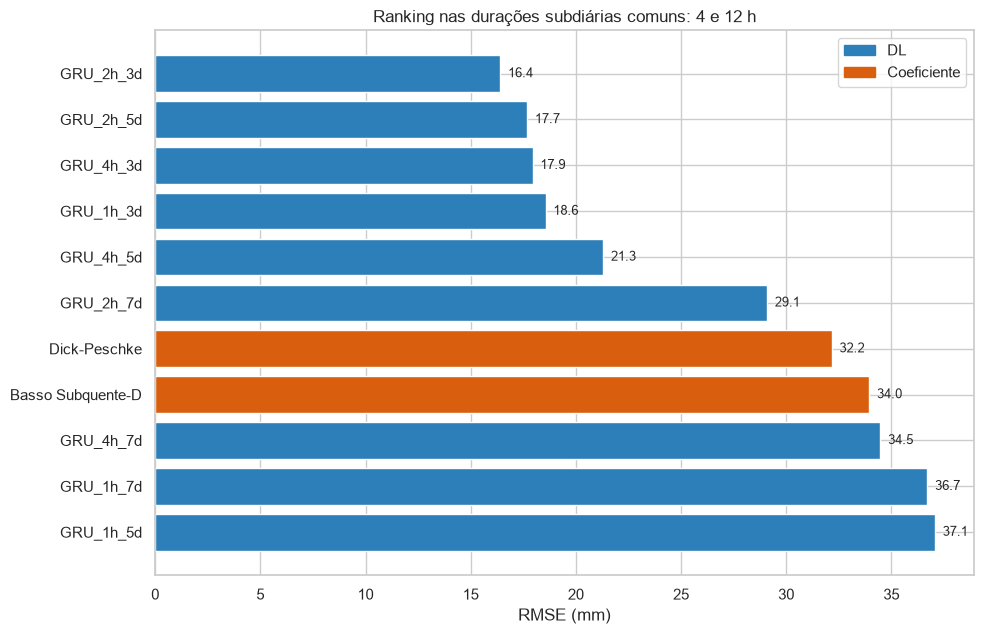

In [9]:
# 8.1 Ranking de RMSE nas durações subdiárias comuns (4 e 12 h)
ordem = ranking_comum_subdiario.sort_values("rmse_mm", ascending=True)
cores = ordem["grupo"].map({"DL": "#2C7FB8", "Coeficiente": "#D95F0E"})

fig, ax = plt.subplots(figsize=(10, 6.5))
barras = ax.barh(ordem["serie"], ordem["rmse_mm"], color=cores)
ax.invert_yaxis()
ax.set_xlabel("RMSE (mm)")
ax.set_ylabel("")
ax.set_title("Ranking nas durações subdiárias comuns: 4 e 12 h")
for barra, valor in zip(barras, ordem["rmse_mm"]):
    ax.text(valor + max(ordem["rmse_mm"]) * 0.01, barra.get_y() + barra.get_height()/2,
            f"{valor:.1f}", va="center", fontsize=9)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="#2C7FB8", label="DL"), Patch(color="#D95F0E", label="Coeficiente")])
fig.tight_layout()
fig.savefig(PASTA_SAIDA / "ranking_rmse_comum_4h_12h.png", dpi=220, bbox_inches="tight")
plt.show()

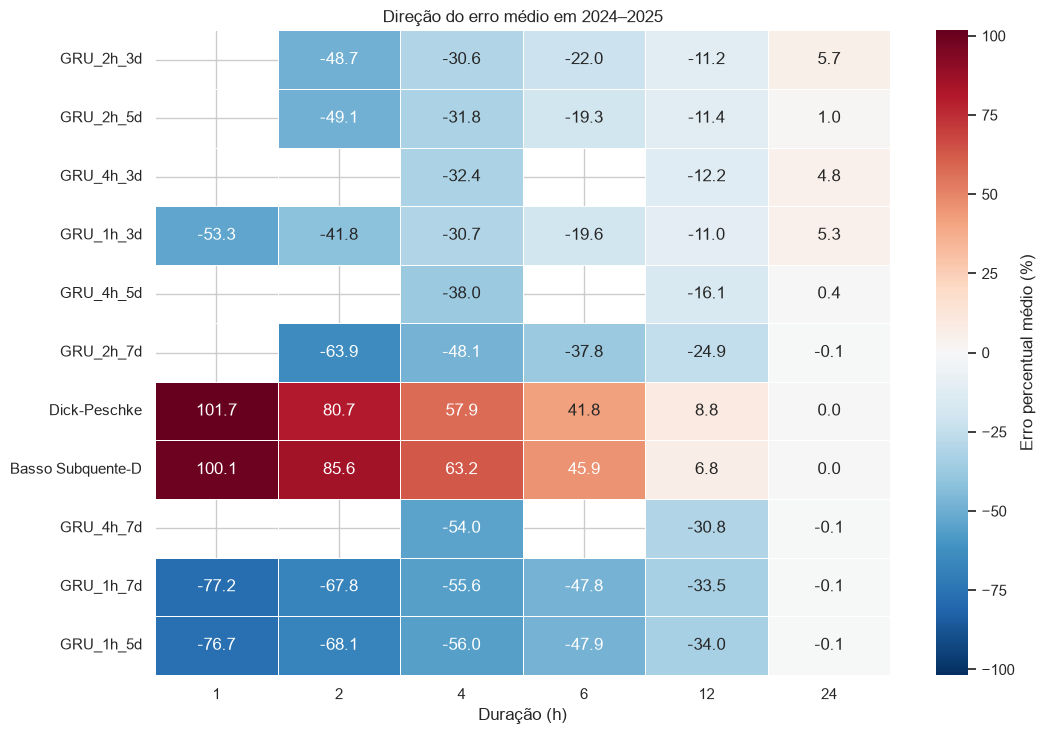

In [10]:
# 8.2 Erro percentual médio de 2024–2025: azul subestima, vermelho superestima
matriz_erro = detalhes.pivot_table(
    index="serie", columns="duracao_h", values="erro_pct", aggfunc="mean"
).reindex(columns=DURACOES_HORAS)
ordem_heatmap = ranking_comum_subdiario["serie"].tolist()
matriz_erro = matriz_erro.reindex(ordem_heatmap)
limite = np.nanmax(np.abs(matriz_erro.to_numpy()))

fig, ax = plt.subplots(figsize=(11, 7.5))
sns.heatmap(
    matriz_erro,
    cmap="RdBu_r",
    center=0,
    vmin=-limite,
    vmax=limite,
    annot=True,
    fmt=".1f",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Erro percentual médio (%)"},
    ax=ax,
)
ax.set_xlabel("Duração (h)")
ax.set_ylabel("")
ax.set_title("Direção do erro médio em 2024–2025")
fig.tight_layout()
fig.savefig(PASTA_SAIDA / "mapa_erros_percentuais.png", dpi=220, bbox_inches="tight")
plt.show()

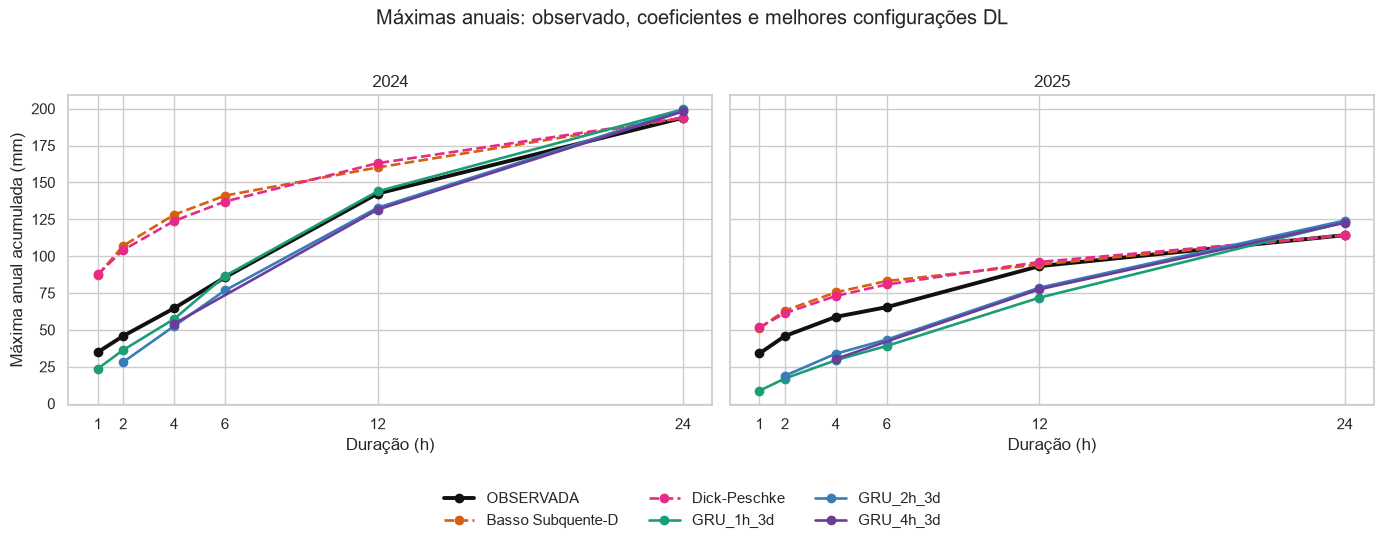

In [11]:
# 8.3 Observado, coeficientes e melhor DL de cada resolução
series_destaque = ["OBSERVADA", "Basso Subquente-D", "Dick-Peschke"]
series_destaque += melhores_dl_resolucao["serie"].drop_duplicates().tolist()
curvas = dados_longos[dados_longos["serie"].isin(series_destaque)].dropna(subset=["estimado_mm"])

fig, eixos = plt.subplots(1, len(ANOS), figsize=(14, 5.2), sharey=True)
if len(ANOS) == 1:
    eixos = [eixos]
paleta = {
    "OBSERVADA": "#111111",
    "Basso Subquente-D": "#D95F0E",
    "Dick-Peschke": "#E7298A",
}
cores_dl = ["#1B9E77", "#377EB8", "#6A3D9A"]
for serie, cor in zip(melhores_dl_resolucao["serie"].drop_duplicates(), cores_dl):
    paleta[serie] = cor

for ax, ano in zip(eixos, ANOS):
    base_ano = curvas[curvas["ano"].eq(ano)]
    for serie in series_destaque:
        linha = base_ano[base_ano["serie"].eq(serie)].sort_values("duracao_h")
        if linha.empty:
            continue
        estilo = "--" if serie in ["Basso Subquente-D", "Dick-Peschke"] else "-"
        largura = 2.8 if serie == "OBSERVADA" else 1.9
        ax.plot(
            linha["duracao_h"], linha["estimado_mm"], marker="o",
            linewidth=largura, linestyle=estilo, color=paleta.get(serie), label=serie,
        )
    ax.set_xticks(DURACOES_HORAS)
    ax.set_xlabel("Duração (h)")
    ax.set_title(str(ano))
eixos[0].set_ylabel("Máxima anual acumulada (mm)")
handles, labels = eixos[-1].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False)
fig.suptitle("Máximas anuais: observado, coeficientes e melhores configurações DL", y=1.02)
fig.tight_layout(rect=[0, 0.13, 1, 1])
fig.savefig(PASTA_SAIDA / "curvas_comparativas.png", dpi=220, bbox_inches="tight")
plt.show()

## 9. Interpretação automática

In [12]:
melhor_dl_comum = ranking_comum_subdiario.query("grupo == 'DL'").iloc[0]
coef_comum = ranking_comum_subdiario.query("grupo == 'Coeficiente'").set_index("serie")
coef_sub = metricas_subdiarias.query("grupo == 'Coeficiente'").set_index("serie")

linhas_resumo = [
    "RESUMO AUTOMÁTICO — MÁXIMAS ANUAIS 2024–2025",
    "",
    "1. O ranking principal exclui 24 h e usa 4 e 12 h, as durações subdiárias disponíveis em todas as resoluções.",
    (
        f"2. Melhor configuração DL no escopo comum: {melhor_dl_comum['serie']}, "
        f"RMSE = {melhor_dl_comum['rmse_mm']:.2f} mm, MAE = {melhor_dl_comum['mae_mm']:.2f} mm, "
        f"ME = {melhor_dl_comum['erro_medio_mm']:.2f} mm e viés = {melhor_dl_comum['vies_pct']:.2f}%."
    ),
]

numero_item = 3
for metodo in ["Basso Subquente-D", "Dick-Peschke"]:
    if metodo in coef_sub.index:
        m = coef_sub.loc[metodo]
        comum = coef_comum.loc[metodo]
        reducao_rmse = 100 * (comum["rmse_mm"] - melhor_dl_comum["rmse_mm"]) / comum["rmse_mm"]
        linhas_resumo.append(
            f"{numero_item}. {metodo}, considerando todas as durações subdiárias, apresentou "
            f"RMSE = {m['rmse_mm']:.2f} mm, ME = {m['erro_medio_mm']:.2f} mm, "
            f"viés = {m['vies_pct']:.2f}% e superestimou {m['superestimacoes_pct']:.1f}% dos casos. "
            f"Nas durações comuns de 4 e 12 h, o melhor DL reduziu o RMSE em "
            f"{reducao_rmse:.1f}% em relação a esse método."
        )
        numero_item += 1

linhas_resumo.append("")
linhas_resumo.append("Melhores configurações DL por resolução:")
for _, linha in melhores_dl_resolucao.iterrows():
    direcao = "subestimação" if linha["erro_medio_mm"] < 0 else "superestimação"
    linhas_resumo.append(
        f"- {int(linha['resolucao_avaliada_h'])} h: {linha['serie']} — "
        f"RMSE {linha['rmse_mm']:.2f} mm, ME {linha['erro_medio_mm']:.2f} mm "
        f"({direcao})."
    )

linhas_resumo += [
    "",
    "Leitura metodológica:",
    "- ME e viés negativos indicam subestimação; positivos indicam superestimação.",
    "- RMSE e MAE menores indicam maior proximidade das máximas observadas.",
    "- O resultado de 24 h não deve sustentar sozinho a superioridade de um método, pois é a escala diária de partida.",
    "- Como existem somente dois anos, os resultados são descritivos do teste de 2024–2025 e não demonstram significância estatística nem desempenho climatológico de longo prazo.",
]

texto_resumo = "\n".join(linhas_resumo)
print(texto_resumo)
(PASTA_SAIDA / "resumo_interpretacao.txt").write_text(texto_resumo, encoding="utf-8")

RESUMO AUTOMÁTICO — MÁXIMAS ANUAIS 2024–2025

1. O ranking principal exclui 24 h e usa 4 e 12 h, as durações subdiárias disponíveis em todas as resoluções.
2. Melhor configuração DL no escopo comum: GRU_2h_3d, RMSE = 16.41 mm, MAE = 15.32 mm, ME = -15.32 mm e viés = -17.08%.
3. Basso Subquente-D, considerando todas as durações subdiárias, apresentou RMSE = 38.78 mm, ME = 31.97 mm, viés = 47.68% e superestimou 100.0% dos casos. Nas durações comuns de 4 e 12 h, o melhor DL reduziu o RMSE em 51.7% em relação a esse método.
4. Dick-Peschke, considerando todas as durações subdiárias, apresentou RMSE = 37.09 mm, ME = 30.78 mm, viés = 45.91% e superestimou 100.0% dos casos. Nas durações comuns de 4 e 12 h, o melhor DL reduziu o RMSE em 49.0% em relação a esse método.

Melhores configurações DL por resolução:
- 1 h: GRU_1h_3d — RMSE 19.38 mm, ME -15.68 mm (subestimação).
- 2 h: GRU_2h_3d — RMSE 18.29 mm, ME -17.10 mm (subestimação).
- 4 h: GRU_4h_3d — RMSE 17.94 mm, ME -16.40 mm (subestimação)

1461

## 10. Exportação dos resultados

In [ ]:
arquivos_saida = {
    "erros_detalhados.csv": detalhes,
    "metricas_todas_duracoes_disponiveis.csv": metricas_todas,
    "metricas_subdiarias_disponiveis.csv": metricas_subdiarias,
    "ranking_comum_subdiario_4h_12h.csv": ranking_comum_subdiario,
    "ranking_comum_4h_12h_24h.csv": ranking_comum_com_24h,
    "ranking_subdiario_por_resolucao.csv": ranking_por_resolucao,
    "melhores_dl_por_resolucao.csv": melhores_dl_resolucao,
    "comparacao_melhores_dl_coeficientes.csv": comparacao_melhores_dl,
    "metricas_por_duracao.csv": metricas_por_duracao,
    "metricas_por_ano.csv": metricas_por_ano,
}

for nome, tabela in arquivos_saida.items():
    caminho = PASTA_SAIDA / nome
    tabela.to_csv(caminho, sep=";", decimal=",", index=False, encoding="utf-8-sig")

print("Arquivos criados em:", PASTA_SAIDA.resolve())
for caminho in sorted(PASTA_SAIDA.iterdir()):
    print(" -", caminho.name)